# Decaimiento de la discriminación, fuga, monotonicidad rota y concentración

**Pregunta:** ¿Qué tan grande debe ser una pérdida de discriminación, qué tan fuerte una fuga, qué tan rota una monotonicidad y qué tan concentrada una distribución de calificaciones para que las pruebas de validación las detecten, y con qué frecuencia?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 a 03 de este tema (la tasa, el tamaño de cada prueba, la escalera de potencia)
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este notebook puedes:

- medir la potencia de la prueba del BCE del AUC frente a su valor inicial y de la prueba de DeLong a lo largo de una escalera de caídas de AUC, y leer la caída que cada una detecta con 80 % de potencia;
- mostrar que una prueba de AUC que trata el AUC de desarrollo como un número conocido rechaza de más cuando ese AUC es estimado;
- relacionar una fuga con la inflación exacta del AUC que causa y con la potencia de la prueba de AUC y del índice de estabilidad de la característica (CSI);
- plantar una ruptura de monotonicidad en una matriz de migración, correr las pruebas z de migración y leer su potencia según el tamaño de la ruptura y de la muestra;
- evaluar el estadístico de concentración del BCE sobre cada redistribución de los grados y ver que no puede alcanzar su valor crítico.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son cuatro familias del caso C22, validar al validador, cada una con un defecto de severidad conocida plantado en datos sorteados por un generador de verdad conocida de `riskvalidation.generators` (licencia MIT, clase `generated`): `discrimination-decay` baja el AUC actual desde el valor de desarrollo de 0,80, con 150 incumplidores entre 5.000 deudores; `leakage` agrega una variable que separa a los incumplidores en desarrollo y no al decidir; `broken-monotonicity` eleva una celda de una matriz de migración de siete grados sobre su vecina más cercana; `concentration` mueve una fracción de cada grado al grado modal de diez grados.

- **Archivos que se leen:** `data/derived/C22/discrimination-decay.json`, `leakage.json`, `broken-monotonicity.json` y `concentration.json`, claves `outputs` y `provenance`.
- **Qué se toma de ellos:** las escaleras, y la configuración del generador y la semilla de cada peldaño, desde las cuales el motor vuelve a sortear los conjuntos aquí.

La celda siguiente carga los cuatro archivos e imprime las versiones del motor.

In [2]:
# Cargar las cuatro familias de defectos e indexar sus simulaciones por familia y clave
LANG = "es"
ROOT = Path("../../..").resolve()
names = ("discrimination-decay", "leakage", "broken-monotonicity", "concentration")
families = {n: json.loads((ROOT / "data" / "derived" / "C22" / f"{n}.json").read_text(encoding="utf-8")) for n in names}
rows = {n: {row["key"]: row for row in fam["outputs"]["simulations"]} for n, fam in families.items()}
for n in names:
    version = families[n]["provenance"]["riskvalidation_version"]
    print(f"{n:22s} {len(rows[n]):2d} simulaciones | calculado con {version} | instalado {rv.__version__}")

discrimination-decay   21 simulaciones | calculado con 1.0.1 | instalado 1.0.1
leakage                14 simulaciones | calculado con 1.0.1 | instalado 1.0.1
broken-monotonicity    24 simulaciones | calculado con 1.0.1 | instalado 1.0.1
concentration          12 simulaciones | calculado con 1.0.1 | instalado 1.0.1


## Método

**La prueba de AUC del BCE.** Con $\mathrm{AUC}_\text{ini}$ el AUC de desarrollo y $\mathrm{AUC}_\text{act}$ el actual, el BCE trata el valor de desarrollo como un número conocido y contrasta

$$S = \frac{\mathrm{AUC}_\text{ini} - \mathrm{AUC}_\text{act}}{s},$$

con $s$ el error estándar del AUC actual. La prueba de DeLong compara dos AUC medidos sobre la misma muestra mediante sus errores estándar correlacionados. **Las pruebas z de migración** comparan cada celda de una matriz de migración con sus vecinas y ajustan los valores p por el número de celdas. **La prueba de concentración** mira el coeficiente de variación de las frecuencias por grado. Para cada defecto se corre una escalera de severidad con `simulate` del motor y la tasa de rechazo al 5 % es la potencia; el peldaño sin defecto es el tamaño.

### Parte A, paso 1: qué caída de AUC se detecta

La familia `discrimination-decay` baja el AUC actual desde 0,80 entre 0 y 0,08 con 150 incumplidores. La celda siguiente simula la prueba del BCE y la de DeLong en cada peldaño, 500 repeticiones cada una, imprime la potencia a lo largo de la escalera y la caída con que cada una cruza 80 % por interpolación lineal, y dibuja ambas curvas.

caídas de AUC de la escalera: [0.0, 0.01, 0.02, 0.03, 0.05, 0.08]
disc.auc_vs_initial  [0.022, 0.11, 0.26, 0.478, 0.8, 0.986] | caída con 80 % de potencia 0.05
disc.delong          [0.044, 0.076, 0.194, 0.358, 0.704, 0.966] | caída con 80 % de potencia 0.061


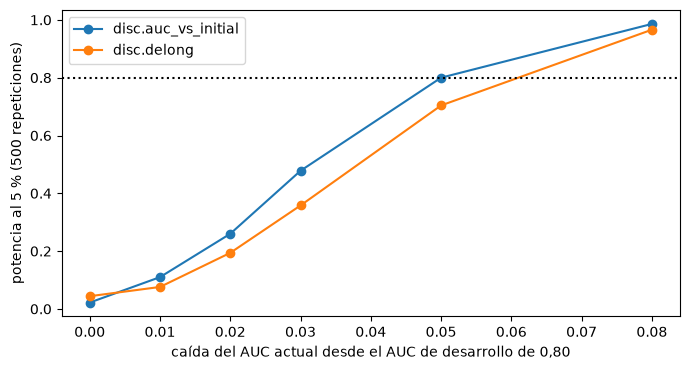

In [3]:
# Simular la prueba de AUC del BCE y DeLong a lo largo de la escalera de caídas de AUC
from riskvalidation.generators.scores import BinormalScores
from riskvalidation.harness.run import simulate

decay = families["discrimination-decay"]["outputs"]
drops = decay["ladder"]["values"]
power = {"disc.auc_vs_initial": [], "disc.delong": []}
for drop in drops:
    for test in power:
        row = rows["discrimination-decay"][f"{test}@d{drop:g}"]
        generator = BinormalScores(**decay["generators"][row["generator"]]["config"])
        power[test].append(simulate(test, generator, n_rep=500, seed=row["seed"]).rates["p<0.05"].rate)
fig, ax = plt.subplots(figsize=(7, 3.8))
print("caídas de AUC de la escalera:", drops)
for test, values in power.items():
    ax.plot(drops, values, "o-", label=test)
    caught = float(np.interp(0.8, np.maximum.accumulate(values), drops))
    print(f"{test:20s}", [round(v, 3) for v in values], "| caída con 80 % de potencia", round(caught, 4))
ax.axhline(0.8, color="black", linestyle=":")
ax.set_xlabel("caída del AUC actual desde el AUC de desarrollo de 0,80")
ax.set_ylabel("potencia al 5 % (500 repeticiones)")
ax.legend()
fig.tight_layout()
plt.show()

En la escalera de caídas 0; 0,01; 0,02; 0,03; 0,05 y 0,08, la prueba del BCE tiene potencia 0,022; 0,110; 0,260; 0,478; 0,800 y 0,986, de modo que detecta una caída de 5 puntos de AUC cuatro veces de cada cinco y una de 2 puntos una vez de cada cuatro. La prueba de DeLong es menos potente, de 0,044 a 0,966, y cruza 80 % con una caída de 0,061. La prueba del BCE se beneficia de tomar el AUC de desarrollo como exacto: ese supuesto quita una fuente de varianza, y el paso siguiente muestra lo que cuesta.

### Parte A, paso 2: el AUC de desarrollo también es una estimación

En la práctica el AUC de desarrollo se estimó sobre una muestra de desarrollo y lleva su propio error, que la forma del BCE ignora. El generador devuelve la varianza del AUC de desarrollo con cada sorteo, y una forma extendida de la prueba la suma. La celda siguiente mide el tamaño de la prueba, sin caída real, con una muestra de desarrollo dieciséis veces la actual (`m16`), con una igual (`m1`) y con la forma extendida en la igual (`m1-extended`).

In [4]:
# Tamaño de la prueba de AUC del BCE con el AUC de desarrollo estimado, forma del BCE y extendida
extended = lambda d: {"auc_initial": d["auc_initial"], "risk": d["risk"], "defaults": d["defaults"],
                      "auc_initial_variance": d["development_auc_variance"]}
for tag, feed in (("m16", None), ("m1", None), ("m1-extended", extended)):
    row = rows["discrimination-decay"][f"disc.auc_vs_initial@{tag}"]
    generator = BinormalScores(**decay["generators"][row["generator"]]["config"])
    run = simulate("disc.auc_vs_initial", generator, n_rep=1000, seed=row["seed"], feed=feed)
    measured = run.rates["p<0.05"]
    print(f"{tag:12s} | muestra actual sobre de desarrollo {row['x']:.3f}", end=" | ")
    print(f"tamaño al 5 % {measured.rate:.4f}")

m16          | muestra actual sobre de desarrollo 0.062 | tamaño al 5 % 0.0470
m1           | muestra actual sobre de desarrollo 1.000 | tamaño al 5 % 0.1270
m1-extended  | muestra actual sobre de desarrollo 1.000 | tamaño al 5 % 0.0590


Con una muestra de desarrollo dieciséis veces mayor que la actual el tamaño es 0,0470, cerca de su nivel, porque entonces el AUC de desarrollo es casi exacto y el supuesto del BCE cuesta poco. Con muestras iguales la forma del BCE rechaza un modelo correcto el 0,1270 de las veces con un 5 % nominal, y la forma extendida que suma la varianza de desarrollo lo devuelve a 0,0590. La forma del BCE es exacta solo cuando el AUC de desarrollo se conoce; con muestras iguales más que duplica su nivel.

### Parte B, paso 3: lo que hace una fuga a las pruebas

En la familia `leakage` una variable se desplaza para los incumplidores en la fuga $\lambda$ en desarrollo y no al decidir, de modo que el AUC del modelo se infla en desarrollo y cae cuando la fuga desaparece. El `truth()` del generador da ambos AUC de forma exacta. La celda siguiente calcula la inflación del AUC de cada peldaño, simula sobre él la prueba de AUC y el CSI, 500 repeticiones cada una, y dibuja la inflación y las dos curvas de potencia.

fuga 0.00 | inflación del AUC 0.0000 | prueba de AUC 0.044 | CSI 0.040
fuga 0.25 | inflación del AUC 0.0426 | prueba de AUC 0.642 | CSI 0.064
fuga 0.50 | inflación del AUC 0.0819 | prueba de AUC 0.980 | CSI 0.074
fuga 1.00 | inflación del AUC 0.1499 | prueba de AUC 1.000 | CSI 0.138
fuga 1.50 | inflación del AUC 0.2029 | prueba de AUC 1.000 | CSI 0.338
fuga 2.00 | inflación del AUC 0.2417 | prueba de AUC 1.000 | CSI 0.564


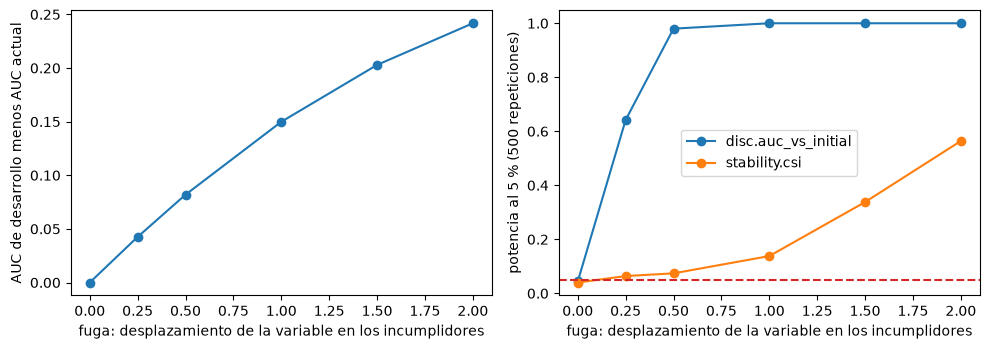

In [5]:
# Inflación exacta del AUC de cada fuga y potencia de la prueba de AUC y del CSI en la escalera
leak = families["leakage"]["outputs"]
leaks = leak["ladder"]["values"]
inflation, hits = [], {"disc.auc_vs_initial": [], "stability.csi": []}
for lam in leaks:
    for test in hits:
        row = rows["leakage"][f"{test}@l{lam:g}"]
        generator = BinormalScores(**leak["generators"][row["generator"]]["config"])
        hits[test].append(simulate(test, generator, n_rep=500, seed=row["seed"]).rates["p<0.05"].rate)
    truth = generator.truth()
    inflation.append(truth["auc_development"] - truth["auc_current"])
    print(f"fuga {lam:4.2f} | inflación del AUC {inflation[-1]:.4f}", end=" | ")
    print(f"prueba de AUC {hits['disc.auc_vs_initial'][-1]:.3f} | CSI {hits['stability.csi'][-1]:.3f}")
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.plot(leaks, inflation, "o-")
left.set_xlabel("fuga: desplazamiento de la variable en los incumplidores")
left.set_ylabel("AUC de desarrollo menos AUC actual")
for test, values in hits.items():
    right.plot(leaks, values, "o-", label=test)
right.axhline(0.05, color="tab:red", linestyle="--")
right.set_xlabel("fuga: desplazamiento de la variable en los incumplidores")
right.set_ylabel("potencia al 5 % (500 repeticiones)")
right.legend()
fig.tight_layout()
plt.show()

Una fuga de 1,0 infla el AUC de desarrollo en 0,1499, y una de 2,0 en 0,2417. La prueba de AUC la nota pronto: su potencia es 0,642 con una fuga de 0,25, que infla el AUC en 0,0426, y 0,980 con 0,50. El CSI, que vigila la propia variable con fuga, es mucho más lento, con 0,064 en 0,25 y solo 0,564 con una fuga de 2,0. Cuando la fuga es la causa de la caída, el AUC ve el efecto mucho antes de que el índice de estabilidad vea la variable que lo causó, y en la práctica un validador debe leer ambos juntos.

### Parte C, paso 4: la ruptura de monotonicidad plantada

Una matriz de migración no debería tener una celda a dos pasos de la diagonal más frecuente que su vecina más cercana. El generador toma una matriz decreciente de siete grados con `decaying_matrix` y `break_monotonicity` fija una celda, del grado 4 al grado 2, en un múltiplo de su vecina. La celda siguiente construye la matriz base y la plantada con una razón de 2, imprime la fila 4 de ambas y las dibuja lado a lado.

fila del grado 4, base:    [0.0143 0.0286 0.0571 0.8    0.0571 0.0286 0.0143]
fila del grado 4, plantada: [0.0143 0.1143 0.0571 0.7143 0.0571 0.0286 0.0143]
celda 4 a 2 sobre su vecina 4 a 3: 2.0


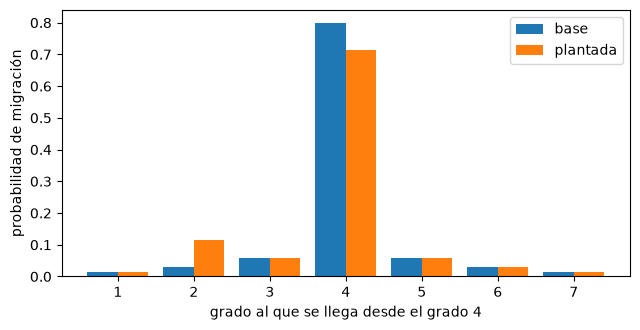

In [6]:
# Construir la matriz base y la de ruptura de monotonicidad plantada, y dibujar la fila 4
from riskvalidation.generators.ratings import break_monotonicity, decaying_matrix
from riskvalidation.validation.rating_system import rating_migration_ztests

base = decaying_matrix(7)
planted = break_monotonicity(base, 3, 1, 2.0)
print("fila del grado 4, base:   ", np.round(base[3], 4))
print("fila del grado 4, plantada:", np.round(planted[3], 4))
print("celda 4 a 2 sobre su vecina 4 a 3:", round(float(planted[3, 1] / planted[3, 2]), 3))
fig, ax = plt.subplots(figsize=(6.5, 3.4))
grades = np.arange(1, 8)
ax.bar(grades - 0.2, base[3], width=0.4, label="base")
ax.bar(grades + 0.2, planted[3], width=0.4, label="plantada")
ax.set_xlabel("grado al que se llega desde el grado 4")
ax.set_ylabel("probabilidad de migración")
ax.legend()
fig.tight_layout()
plt.show()

En la matriz base la fila del grado 4 es 0,0143; 0,0286; 0,0571; 0,8000; 0,0571; 0,0286 y 0,0143: la probabilidad cae de forma continua al crecer la distancia a la diagonal. En la plantada la entrada del grado 2 es 0,1143, el doble del 0,0571 del grado 3, una razón de 2,0 que imprime la celda, y la diagonal cede la masa, 0,7143. El gráfico muestra una sola barra que sobresale de una fila por lo demás monótona, y ese es el defecto que las pruebas z deben encontrar.

### Parte C, paso 5: las pruebas z en una muestra, y su potencia

La celda siguiente sortea 500 deudores por grado de la matriz plantada, corre `rating_migration_ztests` e imprime el número de celdas con un valor p crudo bajo 5 %, el menor valor p ajustado por Holm y la peor celda. Luego simula la prueba sobre la escalera de razones con 500 y 2.000 deudores por grado, 300 repeticiones por peldaño, y dibuja las curvas de potencia.

celdas con p crudo bajo 5 %: 1 | menor p ajustado: 4.06e-04
celda peor: grado 4 al grado 2
razones de la escalera: [1.0, 1.25, 1.5, 2.0, 3.0, 4.0]
  500 deudores por grado: [0.0, 0.007, 0.05, 0.54, 0.997, 1.0]
 2000 deudores por grado: [0.003, 0.08, 0.607, 1.0, 1.0, 1.0]


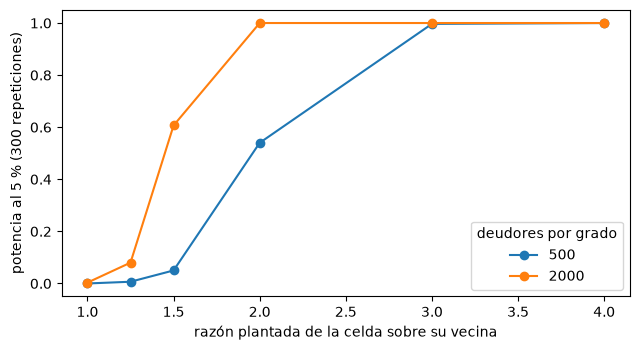

In [7]:
# Correr las pruebas z de migración en una muestra y medir su potencia por razón y tamaño
from riskvalidation.generators.ratings import Migrations

mono = families["broken-monotonicity"]["outputs"]
ratios = mono["ladder"]["values"]
row = rows["broken-monotonicity"]["rating.migration_ztests@r2-n500"]
migrations = Migrations(**mono["generators"][row["generator"]]["config"])
result = rating_migration_ztests(migrations.draw(np.random.default_rng(3))["counts"])
worst = min(result.extras["cells"], key=lambda cell: cell["p_holm"])
print("celdas con p crudo bajo 5 %:", int(result.statistic), "| menor p ajustado:", f"{result.p_value:.2e}")
print("celda peor: grado", worst["from"], "al grado", worst["to"])
print("razones de la escalera:", ratios)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for n_obs in (500, 2000):
    rates = []
    for ratio in ratios:
        item = rows["broken-monotonicity"][f"rating.migration_ztests@r{ratio:g}-n{n_obs}"]
        generator = Migrations(**mono["generators"][item["generator"]]["config"])
        rates.append(simulate(item["test_id"], generator, n_rep=300, seed=item["seed"]).rates["p<0.05"].rate)
    ax.plot(ratios, rates, "o-", label=f"{n_obs}")
    print(f"{n_obs:5d} deudores por grado:", [round(r, 3) for r in rates])
ax.set_xlabel("razón plantada de la celda sobre su vecina")
ax.set_ylabel("potencia al 5 % (300 repeticiones)")
ax.legend(title="deudores por grado")
fig.tight_layout()
plt.show()

En la única muestra sorteada solo 1 celda tiene un valor p crudo bajo 5 %, la peor es la celda del grado 4 al grado 2, y su valor p ajustado es 4,06e-04, suficiente para rechazar al 5 %. A lo largo de la escalera de razones 1; 1,25; 1,5; 2; 3 y 4, con 500 deudores por grado la potencia es 0,000; 0,007; 0,050; 0,540; 0,997 y 1,000, y con 2.000 es 0,003; 0,080; 0,607; 1,000; 1,000 y 1,000. Una celda del doble de su vecina se detecta más de la mitad de las veces con 500 deudores, y una ruptura de 1,5 necesita 2.000 deudores para llegar a 0,607.

### Parte D, paso 6: un estadístico acotado

La familia `concentration` mueve una fracción de la masa de cada grado al grado modal de diez grados. El estadístico de la prueba de concentración del BCE depende solo de las frecuencias, a través de su coeficiente de variación, y se compara con un valor crítico normal. La celda siguiente evalúa `rating_hhi` sobre 201 fracciones movidas, de 0 a 1, halla el mayor estadístico y lo pone junto al valor crítico al 5 %, y dibuja el estadístico en función de la fracción.

coeficiente de variación de las frecuencias de desarrollo: 0.6017
mayor estadístico: 1.0913 con la fracción 0.375
valor crítico al 5 %: 1.6449


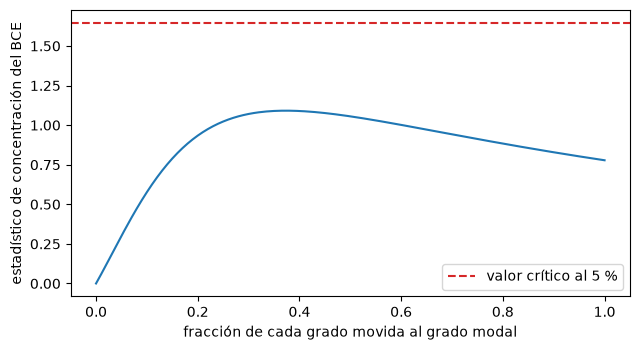

In [8]:
# Evaluar el estadístico de concentración del BCE con cada fracción movida al grado modal
from riskvalidation.generators.ratings import concentrate
from riskvalidation.validation.rating_system import concentration, rating_hhi

conc = families["concentration"]["outputs"]
initial = np.array(conc["generators"]["grades-10-c0.5"]["config"]["initial"])
cv_initial, hi_initial = concentration(initial)
shares = np.linspace(0.0, 1.0, 201)
statistics = np.array([rating_hhi(concentrate(initial, s), initial).statistic for s in shares])
best = int(np.argmax(statistics))
print("coeficiente de variación de las frecuencias de desarrollo:", round(cv_initial, 4))
print("mayor estadístico:", round(float(statistics[best]), 4), "con la fracción", shares[best])
print("valor crítico al 5 %:", round(float(stats.norm.isf(0.05)), 4))
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(shares, statistics)
ax.axhline(stats.norm.isf(0.05), color="tab:red", linestyle="--", label="valor crítico al 5 %")
ax.set_xlabel("fracción de cada grado movida al grado modal")
ax.set_ylabel("estadístico de concentración del BCE")
ax.legend()
fig.tight_layout()
plt.show()

Las frecuencias de desarrollo tienen un coeficiente de variación de 0,6017, y a medida que crece la fracción movida el estadístico sube, alcanza su máximo de 1,0913 con una fracción de 0,375 y luego cae cuando la distribución colapsa en un solo grado, donde el coeficiente de variación está acotado. El valor crítico al 5 % es 1,6449, de modo que ninguna redistribución de estos diez grados, por extrema que sea, puede hacer rechazar a la prueba. Una prueba cuyo estadístico no puede alcanzar su umbral tiene potencia cero por construcción, sean cuales sean los datos.

### Parte D, paso 7: la potencia de la prueba de concentración y de la chi-cuadrado

La celda siguiente simula la prueba de concentración del BCE y la prueba chi-cuadrado de homogeneidad a lo largo de la escalera de fracciones movidas, 500 repeticiones por peldaño, y dibuja las dos curvas. La prueba chi-cuadrado compara toda la distribución de grados con la de desarrollo, así que es un contraste natural.

fracciones de la escalera: [0.0, 0.01, 0.02, 0.05, 0.1, 0.5]
rating.hhi       [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
stability.chi2   [0.056, 0.082, 0.226, 0.956, 1.0, 1.0]


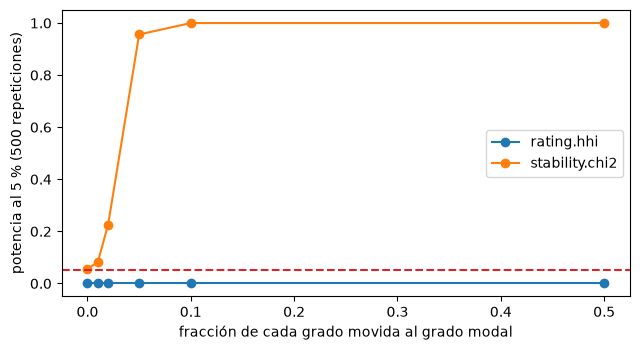

In [9]:
# Medir la potencia de la prueba de concentración y de la chi-cuadrado a lo largo de la fracción movida
from riskvalidation.generators.ratings import GradeFrequencies

moved = conc["ladder"]["values"]
print("fracciones de la escalera:", moved)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for test in ("rating.hhi", "stability.chi2"):
    rates = []
    for share in moved:
        item = rows["concentration"][f"{test}@c{share:g}"]
        generator = GradeFrequencies(**conc["generators"][item["generator"]]["config"])
        rates.append(simulate(test, generator, n_rep=500, seed=item["seed"]).rates["p<0.05"].rate)
    ax.plot(moved, rates, "o-", label=test)
    print(f"{test:16s}", [round(r, 3) for r in rates])
ax.axhline(0.05, color="tab:red", linestyle="--")
ax.set_xlabel("fracción de cada grado movida al grado modal")
ax.set_ylabel("potencia al 5 % (500 repeticiones)")
ax.legend()
fig.tight_layout()
plt.show()

La prueba de concentración tiene una potencia de 0,000 en cada peldaño, desde ningún desplazamiento hasta la mitad de la masa de cada grado movida al modal, tal como predijo el estadístico acotado. La prueba chi-cuadrado, con los mismos datos, pasa de 0,056 sin desplazamiento a 0,082 con una fracción de 0,01, 0,226 con 0,02, 0,956 con 0,05 y 1,000 con 0,10 y 0,50. Las dos pruebas miran cosas distintas, pero solo una puede ver una distribución que se está colapsando, y un validador que dependa solo de la prueba de concentración nunca recibiría una advertencia.

## Resultados

**Respuesta:** Con 150 incumplidores, la prueba del BCE detecta una caída de 5 puntos de AUC con potencia 0,800 y la de DeLong necesita una caída de 0,061; una caída de 2 puntos se detecta solo el 0,260 de las veces. Una fuga de 0,25 infla el AUC de desarrollo en 0,0426 y la prueba de AUC la detecta con potencia 0,642 mientras el CSI llega a 0,064. Una celda de migración del doble de su vecina se detecta el 0,540 de las veces con 500 deudores por grado y siempre con 2.000. La prueba de concentración del BCE no puede rechazar en absoluto: su mayor estadístico es 1,0913 frente a un valor crítico de 1,6449, mientras la prueba chi-cuadrado llega a 0,956 cuando se mueve el 5 % de la masa.

- **La forma del BCE de la prueba de AUC es anticonservadora con un AUC de desarrollo estimado.** Con muestras iguales su tamaño es 0,1270, y 0,0590 con la forma extendida.
- **El efecto aparece antes que la causa.** La prueba de AUC ve una fuga de 0,25 donde el CSI de la variable con fuga tiene 0,064.
- **Un estadístico acotado es una prueba que no puede funcionar.** La potencia de la prueba de concentración es 0,000 en cada peldaño.

Las pruebas de las otras familias, y las probabilidades de rechazo exactas, están en los notebooks anteriores del tema.

## Resumen

- La prueba de AUC del BCE detecta una caída de 5 puntos de AUC con 150 incumplidores con potencia 0,800, y la de DeLong una de 6 puntos; una caída de 2 puntos pasa inadvertida tres veces de cada cuatro.
- La forma del BCE trata el AUC de desarrollo como un número conocido, y con muestras iguales eso eleva su tamaño a 0,1270; sumar la varianza de desarrollo lo restablece.
- Una fuga se muestra en la prueba de AUC mucho antes que en el CSI de la variable con fuga.
- Las pruebas z de migración detectan una celda del doble de su vecina la mitad de las veces con 500 deudores por grado y siempre con 2.000.
- El estadístico de concentración del BCE queda acotado bajo su valor crítico para estos diez grados, así que la prueba tiene potencia cero.

**Qué probar después.** Repite el paso 6 con las frecuencias de una cartera de cuatro grados y mira si cambia la cota; luego lee el notebook 07.

## Referencias

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, secciones 2.5.4.1, 2.5.5.2 y 2.5.5.3 y Anexo 3.1 (el AUC frente al AUC inicial, las pruebas z de migración, la prueba de concentración). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Hanley, J. A. y McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- Demler, O. V., Pencina, M. J. y D'Agostino, R. B. Sr (2012), Misuse of DeLong test to compare AUCs for nested models, Statistics in Medicine 31(23). https://doi.org/10.1002/sim.5328
- Tasche, D. (2013), The art of probability-of-default curve calibration, Journal of Credit Risk 9(4): la prueba del perfil de incumplimiento. https://doi.org/10.21314/jcr.2013.169
- Morris, T. P., White, I. R. y Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- Este repositorio: `docs/design/features/c22-validator/requirements.md` y `data-pipeline/pipeline/cases/c22_validator.py`, que escribió los artefactos.